# Week 14 Homework: ARIA v9.5 - The Resilience Monitor


1. **Landsat harmonization + NDVI 時序**：把 L5/L7/L8/L9 的 band 名稱統一、套用 scale factor 與 QA cloud/shadow mask，建立 2000-2026 年度 NDVI 趨勢圖，並標示 2024 花蓮地震。
2. **像元層級線性趨勢**：用 `ee.Reducer.linearFit()` 算每個像元 2000-2026 的 NDVI slope，分類 greening、browning、stable，並輸出 GeoTIFF。
3. **桃園埤塘消失分析**：用 MNDWI 偵測水體，做 26 年 water frequency、早期 vs 近期埤塘變化、面積估算，並用 223 個已知埤塘點驗證。
4. **植生 resilience 指標**：以 baseline、impact、recovery 三期 NDVI 計算 recovery ratio，製作恢復力分級圖與統計，最後寫整合摘要。



## 本週作業心得
---
本週作業讓我用 Landsat 長期資料重新理解太魯閣與桃園的環境變化。從 2000-2026 年 NDVI 來看，太魯閣整體呈現長期增綠趨勢。雖然 2024 地震後 NDVI 有下降現象，但放在 26 年尺度中觀察，整體仍維持上升趨勢；若要更精確觀察地震造成的短期影響，則可以搭配上週 Sentinel-2 的六年趨勢分析。結果顯示，平均 slope 約為 +0.0028 NDVI/year，像元分析中約 82.66% 的區域屬於 greening，只有 4.71% 為 browning。這讓我發現，單看地震後短期下降可能會高估災害影響，必須放進長時間背景中判斷。另一方面，桃園 MNDWI 分析顯示水體淨減少約 297.75 ha，代表埤塘消失可能影響都市滯洪與防災韌性。震後 recovery ratio 則顯示太魯閣受損區中仍有約七成屬於惡化或慢速恢復。整體而言，本週作業讓我理解長期趨勢、短期災害與環境韌性需要一起分析。

## 問題回答
---
26 年 Landsat 和 6 年 Sentinel-2 的差異主要在時間尺度與解析度。Landsat 能看出太魯閣長期仍呈現增綠趨勢，因此 2024 地震影響需要放在長期背景中解讀；Sentinel-2 則解析度較高，更適合觀察近期地震或崩塌造成的細部變化。

「韌性」在防災管理中很重要，因為災害後不只要知道哪裡受損，也要知道哪裡恢復快、哪裡恢復慢。透過 recovery ratio，可以找出需要優先監測或復育的區域，讓防災不只是災後判讀，也能評估長期恢復能力。

從 W8 到 W14，ARIA 從單張 NDVI 分析逐步演進到多時期變遷、SAR、分類、Sentinel-2 六年趨勢與 Landsat 26 年監測。這讓我理解遙測分析可以從單一影像擴展成完整的環境與災害監測系統。

## 0. 安裝與匯入套件

這一格準備 Google Earth Engine、geemap、繪圖、表格與下載驗證資料需要的套件。若你在 Colab 跑，建議先執行 `%pip install` 這行。



In [ ]:
import os
import io
import json
import textwrap
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw, ImageFont
import imageio.v2 as imageio

import ee
import geemap

plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25



## 1. 初始化 Earth Engine 與設定研究區

這一格登入 GEE，並建立太魯閣 / 秀林研究區 AOI。若你的 GEE 帳號需要指定 Cloud project，請把 `PROJECT_ID` 改成自己的 project id。



In [2]:
PROJECT_ID = 'moonlit-mesh-479012-e0'  # 例如："ee-your-project-id"；若不需要指定 project 就維持 None


def initialize_ee(project_id=None):
    """Initialize Earth Engine, authenticating only when needed."""
    try:
        if project_id:
            ee.Initialize(project=project_id)
        else:
            ee.Initialize()
    except Exception:
        ee.Authenticate()
        if project_id:
            ee.Initialize(project=project_id)
        else:
            ee.Initialize()


initialize_ee(PROJECT_ID)

# Xiulin / Taroko study area BBOX, same as W13.
TAROKO_BBOX = [
    121.34526379253053,
    24.046021742135874,
    121.85149217685861,
    24.35767637905926,
]
aoi = ee.Geometry.Rectangle(TAROKO_BBOX)


def outline_image(geometry, width=2):
    """Create a simple outline image for a geometry."""
    fc = ee.FeatureCollection([ee.Feature(geometry)])
    return ee.Image().byte().paint(fc, 1, width)

START_DATE = "2000-01-01"
END_DATE = "2027-01-01"  # Query through 2026; GEE only returns data that exists.
YEARS = list(range(2000, 2027))
year_list = ee.List.sequence(2000, 2026)

print("Study area: Xiulin / Taroko")
print("BBOX:", TAROKO_BBOX)
print("Years:", YEARS[0], "-", YEARS[-1], "(2026 is year-to-date if running before 2026-12-31)")



Study area: Xiulin / Taroko
BBOX: [121.34526379253053, 24.046021742135874, 121.85149217685861, 24.35767637905926]
Years: 2000 - 2026 (2026 is year-to-date if running before 2026-12-31)


## 2. Landsat band harmonization、scale factor 與雲遮罩

Landsat 5/7 與 Landsat 8/9 的 band 編號不同，所以先統一成 `Blue, Green, Red, NIR, SWIR1, SWIR2`。接著套用 Collection 2 Level 2 反射率 scale factor：`DN * 0.0000275 - 0.2`，並用 `QA_PIXEL` bit 3 與 bit 4 移除 cloud / cloud shadow。



In [3]:
HARMONIZED_BANDS = ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2"]
SCALE_FACTOR = 0.0000275
ADD_OFFSET = -0.2


def harmonize_l57(image):
    """Rename Landsat 5/7 C2 L2 bands to a shared naming scheme."""
    return (
        image.select(
            ["SR_B1", "SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B7", "QA_PIXEL"],
            ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2", "QA_PIXEL"],
        )
        .copyProperties(image, ["system:time_start", "SPACECRAFT_ID"])
    )


def harmonize_l89(image):
    """Rename Landsat 8/9 C2 L2 bands to the same shared naming scheme."""
    return (
        image.select(
            ["SR_B2", "SR_B3", "SR_B4", "SR_B5", "SR_B6", "SR_B7", "QA_PIXEL"],
            ["Blue", "Green", "Red", "NIR", "SWIR1", "SWIR2", "QA_PIXEL"],
        )
        .copyProperties(image, ["system:time_start", "SPACECRAFT_ID"])
    )


def apply_scale_and_mask(image):
    """Apply C2 L2 reflectance scale factor and mask fill/cloud/shadow pixels."""
    qa = image.select("QA_PIXEL")

    # QA_PIXEL bits: 0 = fill, 3 = cloud, 4 = cloud shadow.
    not_fill = qa.bitwiseAnd(1 << 0).eq(0)
    not_cloud = qa.bitwiseAnd(1 << 3).eq(0)
    not_shadow = qa.bitwiseAnd(1 << 4).eq(0)
    mask = not_fill.And(not_cloud).And(not_shadow)

    spectral = (
        image.select(HARMONIZED_BANDS)
        .multiply(SCALE_FACTOR)
        .add(ADD_OFFSET)
        .clamp(0, 1)
    )

    return spectral.updateMask(mask).copyProperties(image, ["system:time_start", "SPACECRAFT_ID"])


def load_landsat_harmonized(region, start_date=START_DATE, end_date=END_DATE):
    """Load L5/L7/L8/L9, harmonize bands, merge collections, and apply QA masking."""
    l5 = (
        ee.ImageCollection("LANDSAT/LT05/C02/T1_L2")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        .map(harmonize_l57)
    )

    l7 = (
        ee.ImageCollection("LANDSAT/LE07/C02/T1_L2")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        .map(harmonize_l57)
    )

    l8 = (
        ee.ImageCollection("LANDSAT/LC08/C02/T1_L2")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        .map(harmonize_l89)
    )

    l9 = (
        ee.ImageCollection("LANDSAT/LC09/C02/T1_L2")
        .filterBounds(region)
        .filterDate(start_date, end_date)
        .map(harmonize_l89)
    )

    return (
        l5.merge(l7)
        .merge(l8)
        .merge(l9)
        .map(apply_scale_and_mask)
        .sort("system:time_start")
    )


landsat_all = load_landsat_harmonized(aoi)
print("Total Landsat images:", landsat_all.size().getInfo())
print("First image bands:", landsat_all.first().bandNames().getInfo())



Total Landsat images: 882
First image bands: ['Blue', 'Green', 'Red', 'NIR', 'SWIR1', 'SWIR2']


## 3. 建立 NDVI、MNDWI、NBR 指數集合

這一格把每張 Landsat 影像轉成三個作業會用到的指數：NDVI 看植生、MNDWI 看水體、NBR 輔助觀察 disturbance / burn-like signal。



In [4]:
def compute_indices(image):
    """Compute NDVI, MNDWI, and NBR from harmonized reflectance bands."""
    ndvi = image.normalizedDifference(["NIR", "Red"]).rename("NDVI")
    mndwi = image.normalizedDifference(["Green", "SWIR1"]).rename("MNDWI")
    nbr = image.normalizedDifference(["NIR", "SWIR2"]).rename("NBR")
    return ndvi.addBands(mndwi).addBands(nbr).copyProperties(image, ["system:time_start"])


index_collection = landsat_all.map(compute_indices)
ndvi_collection = index_collection.select("NDVI")
mndwi_collection = index_collection.select("MNDWI")
nbr_collection = index_collection.select("NBR")

print("Index collection bands:", index_collection.first().bandNames().getInfo())



Index collection bands: ['NDVI', 'MNDWI', 'NBR']


## 4. 小工具：FeatureCollection 轉 DataFrame 與面積統計

後面的任務會反覆把 GEE 統計結果轉成 pandas 表格，也會反覆計算分類面積；先把這些流程包成小函式。



In [5]:
def ee_fc_to_df(fc):
    """Convert an Earth Engine FeatureCollection to a pandas DataFrame."""
    try:
        df = geemap.ee_to_df(fc)
    except Exception:
        features = fc.getInfo()["features"]
        df = pd.DataFrame([f["properties"] for f in features])
    return df


def area_ha(mask_image, region, scale=30, band_name="area_ha"):
    """Calculate area in hectares where mask_image is true/unmasked."""
    area_img = ee.Image.pixelArea().divide(10000).rename(band_name).updateMask(mask_image)
    return ee.Number(
        area_img.reduceRegion(
            reducer=ee.Reducer.sum(),
            geometry=region,
            scale=scale,
            maxPixels=1e13,
            tileScale=4,
        ).get(band_name)
    )


def safe_percent(part, whole):
    return np.nan if whole in [0, None] or pd.isna(whole) else part / whole * 100



# Task 1. 26-year annual NDVI time series

這一段會計算每一年太魯閣 AOI 的年度 median NDVI，取 AOI 平均後畫出 2000-2026 趨勢圖，並用紅線標出 2024 花蓮地震年。



In [8]:
YEARS = list(range(2000, 2027))

def annual_index_row(year):
    """Compute one year's area-mean NDVI, MNDWI, NBR and image count.

    This runs one reduceRegion at a time to avoid the GEE
    'Too many concurrent aggregations' error.
    """
    start = f"{year}-01-01"
    end = f"{year + 1}-01-01"

    annual_img = index_collection.filterDate(start, end).median()

    stats = annual_img.reduceRegion(
        reducer=ee.Reducer.mean(),
        geometry=aoi,
        scale=30,
        maxPixels=1e13,
        tileScale=4,
    ).getInfo()

    image_count = landsat_all.filterDate(start, end).size().getInfo()

    return {
        "year": year,
        "image_count": image_count,
        "NDVI": stats.get("NDVI"),
        "MNDWI": stats.get("MNDWI"),
        "NBR": stats.get("NBR"),
    }


annual_records = []

for year in YEARS:
    print(f"Computing annual indices for {year}...")
    annual_records.append(annual_index_row(year))

annual_df = pd.DataFrame(annual_records)

for col in ["year", "image_count", "NDVI", "MNDWI", "NBR"]:
    annual_df[col] = pd.to_numeric(annual_df[col], errors="coerce")

annual_df

Computing annual indices for 2000...
Computing annual indices for 2001...
Computing annual indices for 2002...
Computing annual indices for 2003...
Computing annual indices for 2004...
Computing annual indices for 2005...
Computing annual indices for 2006...
Computing annual indices for 2007...
Computing annual indices for 2008...
Computing annual indices for 2009...
Computing annual indices for 2010...
Computing annual indices for 2011...
Computing annual indices for 2012...
Computing annual indices for 2013...
Computing annual indices for 2014...
Computing annual indices for 2015...
Computing annual indices for 2016...
Computing annual indices for 2017...
Computing annual indices for 2018...
Computing annual indices for 2019...
Computing annual indices for 2020...
Computing annual indices for 2021...
Computing annual indices for 2022...
Computing annual indices for 2023...
Computing annual indices for 2024...
Computing annual indices for 2025...
Computing annual indices for 2026...


,year,image_count,NDVI,MNDWI,NBR
0,2000,31,0.524979,-0.262122,0.494581
1,2001,33,0.518961,-0.221952,0.516718
2,2002,31,0.513521,-0.200691,0.518848
3,2003,28,0.519373,-0.245120,0.503632
4,2004,34,0.517646,-0.219592,0.525958
5,2005,27,0.494800,-0.207925,0.504299
6,2006,30,0.501699,-0.195077,0.508589
7,2007,22,0.494150,-0.175128,0.527709
8,2008,37,0.502772,-0.209913,0.505921
9,2009,36,0.514135,-0.214411,0.518161


## Task 1 圖表與趨勢線

這格產生作業需要的年度 NDVI trend plot，圖檔會另存成 `task1_taroko_ndvi_2000_2026.png`。



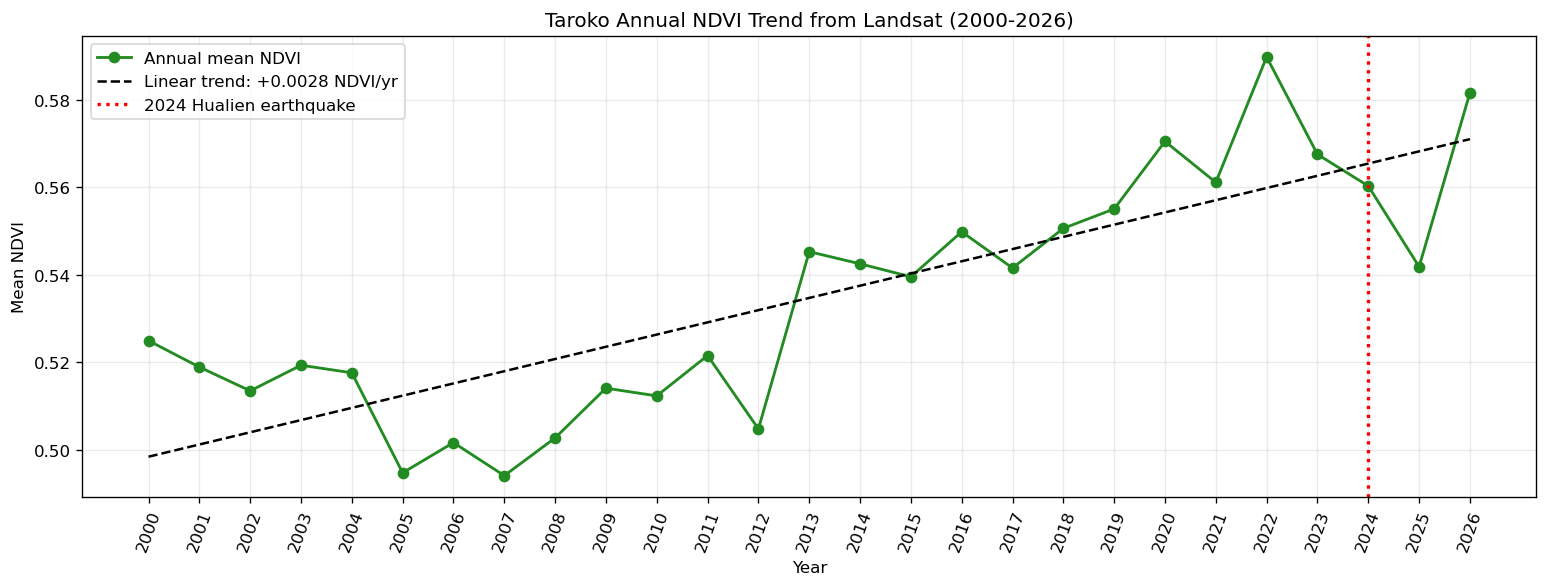

Saved: task1_taroko_ndvi_2000_2026.png
Total Landsat images used: 882
Average images per year: 32.7
Long-term NDVI slope: +0.00279 NDVI/year


In [9]:
valid = annual_df.dropna(subset=["NDVI"]).copy()
coef = np.polyfit(valid["year"], valid["NDVI"], 1)
trendline = np.polyval(coef, annual_df["year"])

fig, ax = plt.subplots(figsize=(13, 5))
ax.plot(
    annual_df["year"],
    annual_df["NDVI"],
    marker="o",
    linewidth=1.7,
    color="forestgreen",
    label="Annual mean NDVI",
)
ax.plot(
    annual_df["year"],
    trendline,
    linestyle="--",
    color="black",
    label=f"Linear trend: {coef[0]:+.4f} NDVI/yr",
)
ax.axvline(2024, color="red", linestyle=":", linewidth=2, label="2024 Hualien earthquake")
ax.set_title("Taroko Annual NDVI Trend from Landsat (2000-2026)")
ax.set_xlabel("Year")
ax.set_ylabel("Mean NDVI")
ax.set_xticks(YEARS)
ax.tick_params(axis="x", rotation=70)
ax.legend()
plt.tight_layout()
plt.savefig("task1_taroko_ndvi_2000_2026.png", dpi=180)
plt.show()

print("Saved: task1_taroko_ndvi_2000_2026.png")
print(f"Total Landsat images used: {int(annual_df['image_count'].sum())}")
print(f"Average images per year: {annual_df['image_count'].mean():.1f}")
print(f"Long-term NDVI slope: {coef[0]:+.5f} NDVI/year")



## Task1 discussion
---
從 2000 到 2026 年的 Landsat 年度平均 NDVI 可以看出，太魯閣 / 秀林研究區整體呈現長期增綠趨勢，線性趨勢約為 +0.0028 NDVI/year。早期 2000-2012 年 NDVI 大多落在 0.49 到 0.52 之間，且在 2005 與 2007 年出現相對低值，顯示該時期植生狀態較不穩定或可能受到颱風、雲量、地表擾動等因素影響。2013 年之後 NDVI 明顯上升，多數年份維持在 0.54 以上，尤其 2020-2023 年達到較高水準，代表研究區在長期尺度上可能有植生恢復或森林覆蓋增加的現象。2024 年花蓮地震發生時，NDVI 約降至 0.56，雖然低於 2022-2023 的高值，但仍高於 2000 年代多數年份，表示地震影響在整個 AOI 平均尺度上可見但並非 26 年中最嚴重的低點。2025 年 NDVI 進一步下降，可能反映震後地表裸露、崩塌地延遲影響或資料時間窗差異；但 2026 年又回升至約 0.58，顯示植生有恢復跡象。整體而言，26 年 Landsat 時序提供了比 W13 六年 Sentinel-2 更完整的背景脈絡，能看出短期擾動其實疊加在長期增綠趨勢之上。

# Task 2. Pixel-level NDVI linear trend

這段把每年的 NDVI median composite 變成一個 annual image collection，加入 `time` band 後用 `linearFit()` 估計每個像元的 NDVI slope。正 slope 代表長期 greening，負 slope 代表 browning。



In [11]:
def annual_ndvi_image(year):
    """Create one annual median NDVI image with a time band for linear regression."""
    year = ee.Number(year).int()
    start = ee.Date.fromYMD(year, 1, 1)
    end = start.advance(1, "year")

    median_ndvi = ndvi_collection.filterDate(start, end).median().rename("NDVI")
    time_band = ee.Image.constant(year).float().rename("time")
    return median_ndvi.addBands(time_band).set("system:time_start", start.millis())


annual_ndvi_col = ee.ImageCollection(year_list.map(annual_ndvi_image))
trend = annual_ndvi_col.select(["time", "NDVI"]).reduce(ee.Reducer.linearFit()).clip(aoi)
slope = trend.select("scale").rename("ndvi_slope")
intercept = trend.select("offset").rename("ndvi_intercept")
valid_year_count = annual_ndvi_col.select("NDVI").count().rename("valid_year_count")

trend_export = slope.addBands(intercept).addBands(valid_year_count)
print("Trend output bands:", trend_export.bandNames().getInfo())



Trend output bands: ['ndvi_slope', 'ndvi_intercept', 'valid_year_count']


## Task 2 趨勢地圖

這格用 diverging palette 顯示 NDVI slope：紅棕色代表 browning，白色接近 stable，綠色代表 greening。



In [12]:
trend_vis = {
    "min": -0.01,
    "max": 0.01,
    "palette": ["8c510a", "d8b365", "f6e8c3", "f5f5f5", "c7eae5", "5ab4ac", "01665e"],
}

Map_trend = geemap.Map(center=[24.20, 121.60], zoom=10)
Map_trend.add_basemap("SATELLITE")
Map_trend.addLayer(slope, trend_vis, "NDVI slope per year")
Map_trend.addLayer(outline_image(aoi), {"palette": ["black"]}, "Taroko AOI")
Map_trend.add_colorbar(trend_vis, label="NDVI slope / year")
Map_trend



Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## Task 2 greening / browning / stable 統計

這格用 slope threshold `±0.001 NDVI/year` 分類像元，並計算各類面積與百分比。



In [13]:
SLOPE_THRESHOLD = 0.001

greening = slope.gt(SLOPE_THRESHOLD).rename("greening")
browning = slope.lt(-SLOPE_THRESHOLD).rename("browning")
stable = slope.gte(-SLOPE_THRESHOLD).And(slope.lte(SLOPE_THRESHOLD)).rename("stable")
valid_slope_mask = slope.mask().rename("valid")

green_area = area_ha(greening, aoi).getInfo()
brown_area = area_ha(browning, aoi).getInfo()
stable_area = area_ha(stable, aoi).getInfo()
total_trend_area = area_ha(valid_slope_mask, aoi).getInfo()

trend_stats_df = pd.DataFrame(
    [
        {"class": "greening", "area_ha": green_area, "percent": safe_percent(green_area, total_trend_area)},
        {"class": "browning", "area_ha": brown_area, "percent": safe_percent(brown_area, total_trend_area)},
        {"class": "stable", "area_ha": stable_area, "percent": safe_percent(stable_area, total_trend_area)},
    ]
)

trend_stats_df



,class,area_ha,percent
0,greening,146747.561565,82.661055
1,browning,8368.636179,4.713947
2,stable,22413.064617,12.624997


## Task 2 GeoTIFF 匯出

作業要求輸出 trend map GeoTIFF。確認前面地圖與統計無誤後，把 `RUN_EXPORTS` 改成 `True` 並執行；匯出會出現在 Google Drive 的 `GEE_Exports` 資料夾。



In [14]:
RUN_EXPORTS = True

if RUN_EXPORTS:
    task = ee.batch.Export.image.toDrive(
        image=trend_export.float(),
        description="taroko_ndvi_trend_2000_2026",
        folder="GEE_Exports",
        fileNamePrefix="taroko_ndvi_trend_2000_2026",
        region=aoi,
        scale=30,
        crs="EPSG:32651",
        maxPixels=1e13,
    )
    task.start()
    print("Started export:", task.status())
else:
    print("RUN_EXPORTS is False. Set it to True to export GeoTIFF to Google Drive.")



Started export: {'state': 'READY', 'description': 'taroko_ndvi_trend_2000_2026', 'priority': 100, 'creation_timestamp_ms': 1779989198307, 'update_timestamp_ms': 1779989198307, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '2S6YHZZY2Q4KIHR7LPU43PWW', 'name': 'projects/moonlit-mesh-479012-e0/operations/2S6YHZZY2Q4KIHR7LPU43PWW'}


## Task 2 discussion
---
從 2000-2026 年的像元層級 NDVI 線性趨勢圖可以看出，太魯閣 / 秀林研究區大部分區域呈現長期增綠趨勢。以 slope 大於 0.001 NDVI/year 作為 greening 門檻時，增綠面積約為 146,747.56 ha，占有效像元的 82.66%；browning 面積約為 8,368.64 ha，僅占 4.71%；stable 區域約為 22,413.06 ha，占 12.62%。這表示雖然局部地區有退化或植生下降現象，但從 26 年長期尺度來看，整體景觀仍以 NDVI 上升為主，和 Task 1 的區域平均 NDVI 正趨勢相互呼應。

空間分布上，greening 像元廣泛分布於研究區內，多數山區與植被覆蓋區呈現淡綠到藍綠色，代表 NDVI 每年緩慢增加。相對地，browning 像元多呈現零星斑塊，集中在河谷、道路、都市邊緣或可能發生崩塌與裸露地變化的位置。這些 browning 區域雖然比例不高，但在地形破碎、坡地擾動或人為開發較明顯的地方仍具有生態與災害監測意義。stable 區域則可能代表植被狀態長期維持穩定，或是 NDVI 變化幅度小於本次設定的 threshold。

與 W13 的 2020-2026 年 Sentinel-2 六年分析相比，W14 的 Landsat 26 年趨勢提供了更完整的長期背景。短期 Sentinel-2 分析可能會受到 2024 花蓮地震、颱風、崩塌或單一年份雲量影響，使某些區域看起來像是快速 browning；但 Landsat 長期趨勢顯示，許多區域其實仍位於長期 greening 軌跡上。因此，W13 較適合觀察近期擾動與細節變化，W14 則更適合判斷這些變化是否超出長期背景波動。兩者互補後，可以同時掌握「短期災害衝擊」與「長期生態恢復或退化趨勢」。



# Task 3. Taoyuan pond disappearance with MNDWI

這段改用桃園 AOI，沿用同一套 Landsat harmonization 與 cloud mask，計算 MNDWI 水體指標，建立 water frequency 與早期 / 近期水體變化。



In [16]:
TAOYUAN_BBOX = [120.94, 24.83, 121.35, 25.08]
TAOYUAN_URBAN_BBOX = [121.00, 24.88, 121.28, 25.05]

aoi_taoyuan = ee.Geometry.Rectangle(TAOYUAN_BBOX)
aoi_taoyuan_urban = ee.Geometry.Rectangle(TAOYUAN_URBAN_BBOX)

landsat_taoyuan = load_landsat_harmonized(aoi_taoyuan)
print("Taoyuan Landsat images:", landsat_taoyuan.size().getInfo())


def compute_mndwi(image):
    """MNDWI = (Green - SWIR1) / (Green + SWIR1)."""
    return image.normalizedDifference(["Green", "SWIR1"]).rename("MNDWI").copyProperties(image, ["system:time_start"])


mndwi_taoyuan = landsat_taoyuan.map(compute_mndwi)



Taoyuan Landsat images: 2498


## Task 3 年度水體與 water frequency

這格把每一年 median MNDWI 大於 0.1 的像元視為水體，再取 2000-2026 平均，得到每個像元出現為水體的頻率。



In [17]:
WATER_THRESHOLD = 0.1


def yearly_water(year):
    year = ee.Number(year).int()
    start = ee.Date.fromYMD(year, 1, 1)
    end = start.advance(1, "year")
    median_mndwi = mndwi_taoyuan.filterDate(start, end).median()
    water = median_mndwi.gt(WATER_THRESHOLD).rename("water")
    return water.set("system:time_start", start.millis())


water_col = ee.ImageCollection(year_list.map(yearly_water))
water_frequency = water_col.mean().rename("water_frequency").clip(aoi_taoyuan)

water_vis = {"min": 0, "max": 1, "palette": ["ffffff", "c6dbef", "6baed6", "2171b5", "08306b"]}

Map_water_freq = geemap.Map(center=[24.96, 121.14], zoom=10)
Map_water_freq.add_basemap("SATELLITE")
Map_water_freq.addLayer(water_frequency, water_vis, "Water frequency 2000-2026")
Map_water_freq.addLayer(outline_image(aoi_taoyuan), {"palette": ["black"]}, "Taoyuan AOI")
Map_water_freq.add_colorbar(water_vis, label="Water occurrence frequency")
Map_water_freq



Map(center=[24.96, 121.14], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

## Task 3 早期 vs 近期埤塘變化

這格比較 2000-2005 與 2021-2026 的水體：早期是水、近期不是水的像元視為 lost ponds；近期新增的水體視為 new water。



In [20]:
early_water = (
    mndwi_taoyuan.filterDate("2000-01-01", "2006-01-01")
    .median()
    .gt(WATER_THRESHOLD)
    .unmask(0)
    .rename("early_water")
)

recent_water = (
    mndwi_taoyuan.filterDate("2021-01-01", "2027-01-01")
    .median()
    .gt(WATER_THRESHOLD)
    .unmask(0)
    .rename("recent_water")
)

lost_ponds = early_water.And(recent_water.Not()).rename("lost_ponds").clip(aoi_taoyuan_urban).selfMask()
new_water = recent_water.And(early_water.Not()).rename("new_water").clip(aoi_taoyuan_urban).selfMask()

lost_area = area_ha(lost_ponds, aoi_taoyuan).getInfo()
new_area = area_ha(new_water, aoi_taoyuan).getInfo()
net_change = new_area - lost_area

pond_change_df = pd.DataFrame(
    [
        {"change_type": "lost_ponds", "area_ha": lost_area},
        {"change_type": "new_water", "area_ha": new_area},
        {"change_type": "net_change_new_minus_lost", "area_ha": net_change},
    ]
)
pond_change_df



,change_type,area_ha
0,lost_ponds,348.524657
1,new_water,50.769911
2,net_change_new_minus_lost,-297.754746


## Task 3 埤塘變化地圖

紅色是早期有水、近期消失的區域；綠色是近期新增或變成水體的區域。



In [21]:
Map_pond_change = geemap.Map(center=[24.96, 121.14], zoom=11)
Map_pond_change.add_basemap("SATELLITE")
Map_pond_change.addLayer(lost_ponds.selfMask(), {"palette": ["red"]}, "Lost ponds: early water -> recent land")
Map_pond_change.addLayer(new_water.selfMask(), {"palette": ["00c853"]}, "New water: early land -> recent water")
Map_pond_change.addLayer(outline_image(aoi_taoyuan_urban), {"palette": ["yellow"]}, "Urban corridor")
Map_pond_change



Map(center=[24.96, 121.14], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright…

## Task 3 使用 223 個已知埤塘點驗證

這格下載題目提供的 GeoJSON，轉成 GEE FeatureCollection，並檢查近期 MNDWI 水體圖是否偵測到這些已知埤塘位置。



In [22]:
PONDS_GEOJSON = "taoyuan_ponds_223.geojson"
PONDS_URL = "https://drive.google.com/uc?id=1qwrIIELIJXbrBL_oCBTcoE-aoWq1bdXw"
DOWNLOAD_POND_POINTS = True

if DOWNLOAD_POND_POINTS and not os.path.exists(PONDS_GEOJSON):
    import gdown

    gdown.download(PONDS_URL, PONDS_GEOJSON, quiet=False)

if os.path.exists(PONDS_GEOJSON):
    try:
        ponds_fc = geemap.geojson_to_ee(PONDS_GEOJSON)
    except Exception:
        with open(PONDS_GEOJSON, "r", encoding="utf-8") as f:
            ponds_geojson = json.load(f)
        pond_features = []
        for feat in ponds_geojson["features"]:
            geom = ee.Geometry(feat["geometry"])
            props = feat.get("properties", {})
            pond_features.append(ee.Feature(geom, props))
        ponds_fc = ee.FeatureCollection(pond_features)

    pond_samples = recent_water.unmask(0).sampleRegions(
        collection=ponds_fc,
        scale=30,
        geometries=True,
    )
    detected = pond_samples.filter(ee.Filter.eq("recent_water", 1)).size()
    total = ponds_fc.size()
    counts = ee.Dictionary({"total": total, "detected": detected}).getInfo()
    detection_rate = counts["detected"] / counts["total"] * 100

    print(f"Known ponds: {counts['total']}")
    print(f"MNDWI detected: {counts['detected']}")
    print(f"Detection rate: {detection_rate:.1f}%")
else:
    detection_rate = np.nan
    print("Pond GeoJSON was not found. Re-run this cell with DOWNLOAD_POND_POINTS=True.")



Downloading...
From: https://drive.google.com/uc?id=1qwrIIELIJXbrBL_oCBTcoE-aoWq1bdXw
To: c:\Users\Ben\Documents\NTU\RSGI\homework13\taoyuan_ponds_223.geojson
100%|██████████| 49.7k/49.7k [00:00<00:00, 24.8MB/s]


Known ponds: 223
MNDWI detected: 199
Detection rate: 89.2%


## Task 3 discussion
---
本題使用 MNDWI 分析桃園地區 2000-2005 年與 2021-2026 年之間的水體變化，並以 MNDWI > 0.1 作為水體判斷門檻。結果顯示，早期為水體但近期轉為非水體的區域約 348.52 ha，近期新增水體約 50.77 ha，淨變化為 -297.75 ha。這表示研究區在過去二十多年中水體面積明顯減少，且埤塘或小型蓄水空間的消失量遠大於新增量。

從空間分布來看，lost ponds 多以零星紅色斑塊分布在桃園都市與農業混合區，許多位置接近建成區、道路或開發邊緣，顯示埤塘消失可能與都市擴張、土地利用轉換及農地開發有關。不過部分紅色區域位於海岸或水陸交界附近，因此仍需注意潮汐、濕地、混合像元與 Landsat 30 m 解析度造成的誤判。

驗證部分使用 223 個已知埤塘點，其中 MNDWI 偵測到 199 個，偵測率為 89.2%，代表此方法對主要埤塘具有不錯的辨識能力。未被偵測到的點位可能是因為埤塘太小、水體混濁、周邊植被或建物造成混合像元，或近期已不再維持明顯水面。

整體而言，桃園埤塘減少不只是土地覆蓋變遷，也可能降低都市防洪韌性。埤塘具有滯洪、蓄水與調節逕流的功能，當小型水體消失時，強降雨期間排水系統壓力可能增加，淹水風險也可能提高。



# Task 4. Vegetation resilience metrics

這段把太魯閣 NDVI 分成三個時期：2020-2023 baseline、2024 impact、2025-2026 recovery，並計算 `Recovery Ratio = (Recovery - Impact) / (Baseline - Impact)`。



In [26]:
baseline_ndvi = ndvi_collection.filterDate("2020-01-01", "2024-01-01").median().rename("baseline_ndvi").clip(aoi)
impact_ndvi = ndvi_collection.filterDate("2024-01-01", "2025-01-01").median().rename("impact_ndvi").clip(aoi)
recovery_ndvi = ndvi_collection.filterDate("2025-01-01", "2027-01-01").median().rename("recovery_ndvi").clip(aoi)

ndvi_drop = baseline_ndvi.subtract(impact_ndvi).rename("baseline_minus_impact")

# Focus on likely damaged pixels: baseline must be at least 0.05 NDVI higher than impact.
DAMAGE_THRESHOLD = 0.05
damage_mask = ndvi_drop.gt(DAMAGE_THRESHOLD).rename("damage_mask").clip(aoi)

recovery_ratio = (
    recovery_ndvi.subtract(impact_ndvi)
    .divide(ndvi_drop)
    .updateMask(damage_mask)
    .rename("recovery_ratio")
    .clamp(-1, 2)
)

print("Recovery ratio ready. Damage threshold:", DAMAGE_THRESHOLD)



Recovery ratio ready. Damage threshold: 0.05


## Task 4 恢復力地圖

Recovery ratio 小於 0 代表持續惡化，0-0.5 是慢速恢復，0.5-1 是部分至接近恢復，大於 1 代表已超過 baseline。



In [27]:
rr_vis = {
    "min": -1,
    "max": 2,
    "palette": ["a50026", "d73027", "fdae61", "ffffbf", "a6d96a", "1a9850", "2166ac"],
}

Map_rr = geemap.Map(center=[24.20, 121.60], zoom=10)
Map_rr.add_basemap("SATELLITE")
Map_rr.addLayer(recovery_ratio, rr_vis, "Recovery ratio")
Map_rr.addLayer(outline_image(aoi), {"palette": ["black"]}, "Taroko AOI")
Map_rr.add_colorbar(rr_vis, label="Recovery ratio")
Map_rr



Map(center=[24.2, 121.6], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright',…

## Task 4 恢復力分級統計

這格計算 damaged pixels 中，各恢復力等級的面積與比例。



In [28]:
rr_degrading = recovery_ratio.lt(0).rename("degrading")
rr_slow = recovery_ratio.gte(0).And(recovery_ratio.lt(0.5)).rename("slow_recovery")
rr_recovering = recovery_ratio.gte(0.5).And(recovery_ratio.lte(1.0)).rename("recovering")
rr_exceeded = recovery_ratio.gt(1.0).rename("exceeded_baseline")

damaged_area = area_ha(damage_mask, aoi).getInfo()
rr_stats = []
for class_name, mask_img in [
    ("degrading", rr_degrading),
    ("slow_recovery_0_to_0.5", rr_slow),
    ("recovering_0.5_to_1.0", rr_recovering),
    ("exceeded_baseline_gt_1.0", rr_exceeded),
]:
    class_area = area_ha(mask_img, aoi).getInfo()
    rr_stats.append(
        {
            "class": class_name,
            "area_ha": class_area,
            "percent_of_damaged": safe_percent(class_area, damaged_area),
        }
    )

rr_stats_df = pd.DataFrame(rr_stats)
print(f"Damaged area: {damaged_area:.1f} ha")
rr_stats_df



Damaged area: 18763.5 ha


,class,area_ha,percent_of_damaged
0,degrading,4376.960446,23.326936
1,slow_recovery_0_to_0.5,8816.500013,46.987386
2,recovering_0.5_to_1.0,3380.070619,18.014029
3,exceeded_baseline_gt_1.0,2182.417643,11.631158


## Task 4 discussion
---
本題以 2020-2023 年作為地震前 baseline，2024 年作為 impact period，2025-2026 年作為 recovery period，利用 NDVI recovery ratio 評估太魯閣地區震後植生恢復情形。結果顯示，受損面積約為 18,763.5 ha，表示 2024 年相對於地震前有明顯 NDVI 下降的區域確實存在。

在受損區域中，約 23.33% 屬於持續惡化，46.99% 屬於慢速恢復，18.01% 已恢復到 baseline 的一半以上，另有 11.63% 超過地震前 baseline。整體來看，接近七成的受損區域仍處於惡化或慢速恢復狀態，顯示震後植生恢復並不均勻。

空間上，低 recovery ratio 多分布在河谷、坡地邊緣與可能受崩塌影響的區域；恢復較好的區域則較零散。這說明雖然 Task 1 和 Task 2 顯示太魯閣長期上有增綠趨勢，但 2024 地震仍造成局部明顯擾動，且部分地區需要更長時間恢復。

## Week 14 整體報告心得
---
本週作業使用 Landsat 2000-2026 年長期資料，分析太魯閣 / 秀林地區的植生變化、震後恢復力，以及桃園埤塘水體變遷。從 Task 1 的年度 NDVI 來看，太魯閣整體呈現長期增綠趨勢，平均 slope 約為 +0.0028 NDVI/year。雖然 2024 花蓮地震後 NDVI 有下降，但放在 26 年尺度下觀察，整體仍維持上升趨勢。

Task 2 的像元層級分析也支持這個結果，約 82.66% 的區域屬於 greening，只有 4.71% 為 browning，代表長期來看大多數地區植生狀態仍在改善。不過局部 browning 可能出現在河谷、道路、崩塌或人為干擾較明顯的區域。與上週 6 年 Sentinel-2 分析相比，Landsat 的優勢是時間長、能看出長期背景；Sentinel-2 則解析度較高，更適合觀察近期地震造成的細部變化。

Task 3 顯示桃園水體淨減少約 297.75 ha，代表埤塘或小型蓄水空間長期減少，可能降低都市滯洪與防洪韌性。Task 4 的 recovery ratio 則顯示太魯閣受損區中仍有約七成屬於惡化或慢速恢復，表示災後恢復並不均勻。

「韌性」在防災管理中很重要，因為災害後不只要知道哪裡受損，也要知道哪裡恢復快、哪裡恢復慢。從 W8 到 W14，ARIA 從單張 NDVI 分析逐步發展到長期趨勢與恢復力監測，讓我理解遙測可以建立更完整的環境與災害監測系統。

# Bonus 1. Multi-index dashboard

這個 bonus 用同一份年度統計表，把 NDVI、MNDWI、NBR 三個指數放在同一張 multi-panel dashboard 中，觀察植生、水文與 disturbance signal 是否同步。



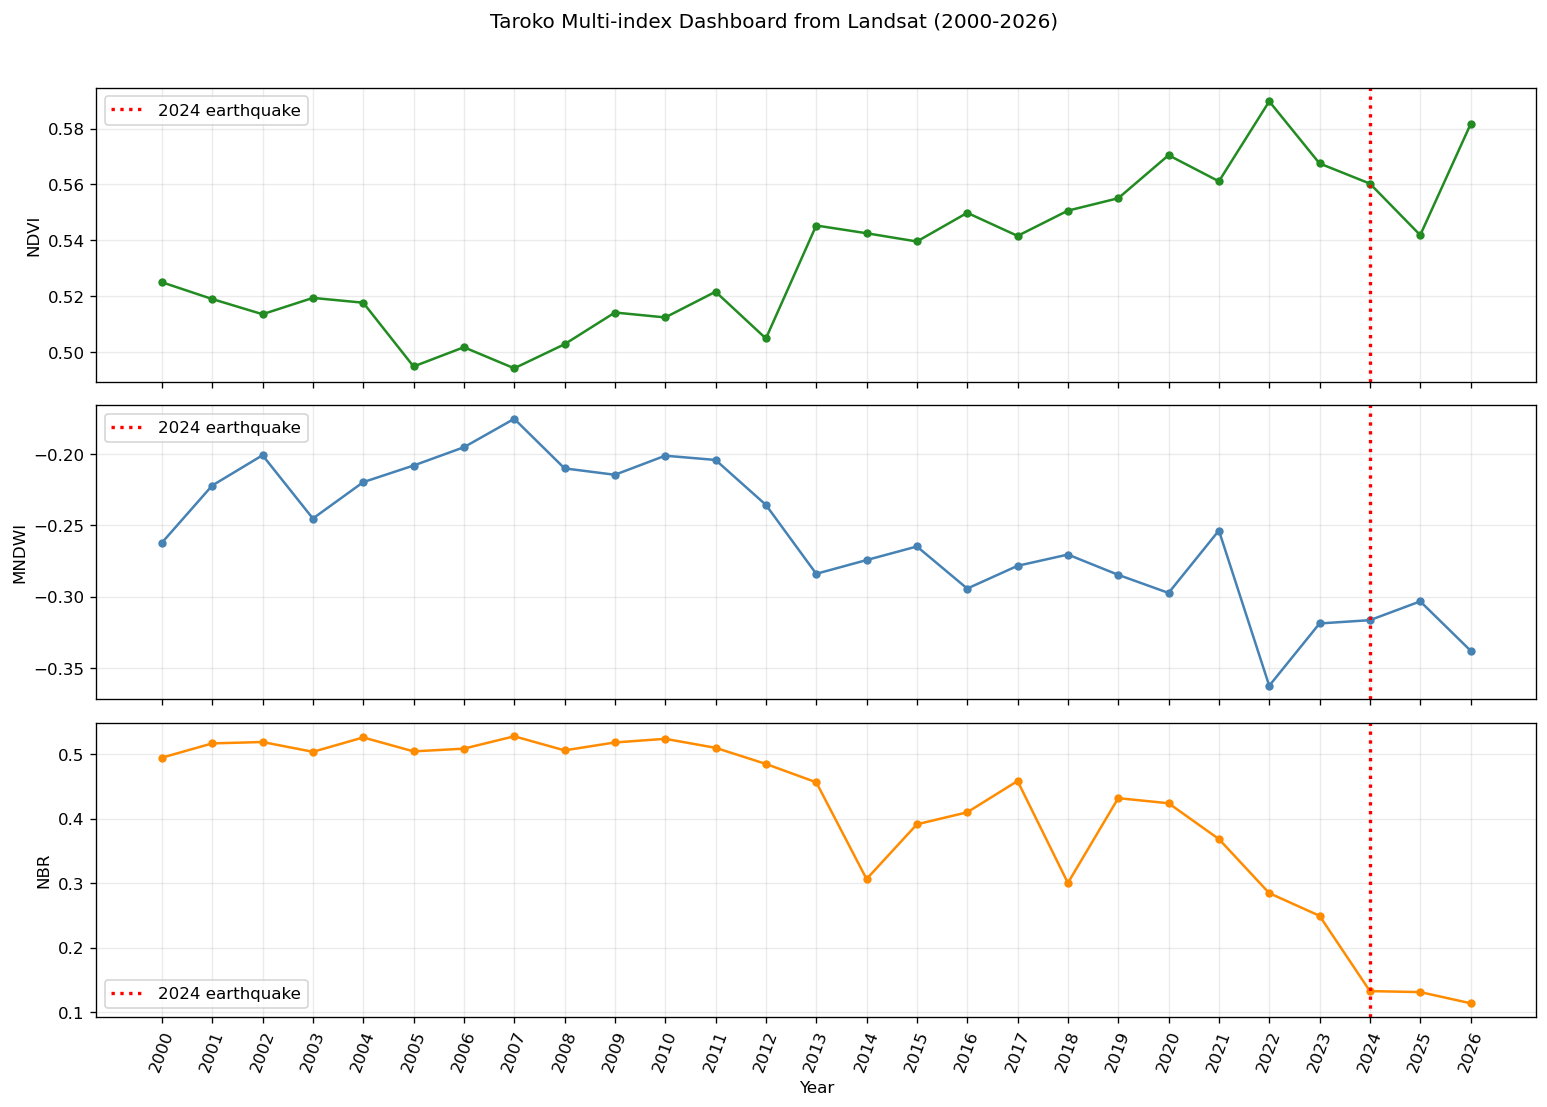

Saved: bonus1_taroko_multi_index_dashboard.png
Index correlation matrix:
        NDVI  MNDWI    NBR
NDVI   1.000 -0.925 -0.747
MNDWI -0.925  1.000  0.803
NBR   -0.747  0.803  1.000


In [31]:
fig, axes = plt.subplots(3, 1, figsize=(13, 9), sharex=True)
indices = ["NDVI", "MNDWI", "NBR"]
colors = ["forestgreen", "steelblue", "darkorange"]

for ax, idx, color in zip(axes, indices, colors):
    ax.plot(annual_df["year"], annual_df[idx], color=color, marker="o", linewidth=1.5, markersize=4)
    ax.axvline(2024, color="red", linestyle=":", linewidth=2, label="2024 earthquake")
    ax.set_ylabel(idx)
    ax.legend(loc="best")

axes[-1].set_xlabel("Year")
axes[-1].set_xticks(YEARS)
axes[-1].tick_params(axis="x", rotation=70)
fig.suptitle("Taroko Multi-index Dashboard from Landsat (2000-2026)", y=1.02)
plt.tight_layout()
plt.savefig("bonus1_taroko_multi_index_dashboard.png", dpi=180)
plt.show()

print("Saved: bonus1_taroko_multi_index_dashboard.png")
print("Index correlation matrix:")
print(annual_df[["NDVI", "MNDWI", "NBR"]].corr().round(3))



# Bonus 2. NDVI 26-year time-lapse animation

這段會從 GEE 下載每一年 NDVI thumbnail，加上年份與事件標籤，輸出 GIF。這會花一些時間，所以預設 `MAKE_GIF=False`；要做 bonus 時改成 `True`。



In [35]:
MAKE_GIF = True
GIF_NAME = "bonus2_taroko_ndvi_2000_2026_timelapse.gif"
EVENT_LABELS = {
    2009: "Morakot",
    2015: "Soudelor",
    2024: "Earthquake",
}
NDVI_PALETTE = ["8c510a", "d8b365", "ffffbf", "66bd63", "1a9850", "006837"]

if MAKE_GIF:
    frames = []
    font = ImageFont.load_default()

    for year in YEARS:
        composite = ndvi_collection.filterDate(f"{year}-01-01", f"{year + 1}-01-01").median()
        thumb_url = composite.getThumbURL(
            {
                "region": aoi,
                "dimensions": 640,
                "min": 0,
                "max": 0.85,
                "palette": NDVI_PALETTE,
                "format": "png",
            }
        )
        response = requests.get(thumb_url, timeout=120)
        response.raise_for_status()
        img = Image.open(io.BytesIO(response.content)).convert("RGB")

        draw = ImageDraw.Draw(img)
        label = str(year)
        if year in EVENT_LABELS:
            label += f" | {EVENT_LABELS[year]}"
        draw.rectangle((8, 8, 210, 34), fill=(0, 0, 0))
        draw.text((14, 14), label, fill="white", font=font)
        frames.append(np.array(img))
        print(year, "OK")

    imageio.mimsave(GIF_NAME, frames, duration=0.8, loop=0)
    print("Saved:", GIF_NAME)
else:
    print("MAKE_GIF is False. Set it to True to generate the animation GIF.")



2000 OK
2001 OK
2002 OK
2003 OK
2004 OK
2005 OK
2006 OK
2007 OK
2008 OK
2009 OK
2010 OK
2011 OK
2012 OK
2013 OK
2014 OK
2015 OK
2016 OK
2017 OK
2018 OK
2019 OK
2020 OK
2021 OK
2022 OK
2023 OK
2024 OK
2025 OK
2026 OK
Saved: bonus2_taroko_ndvi_2000_2026_timelapse.gif
